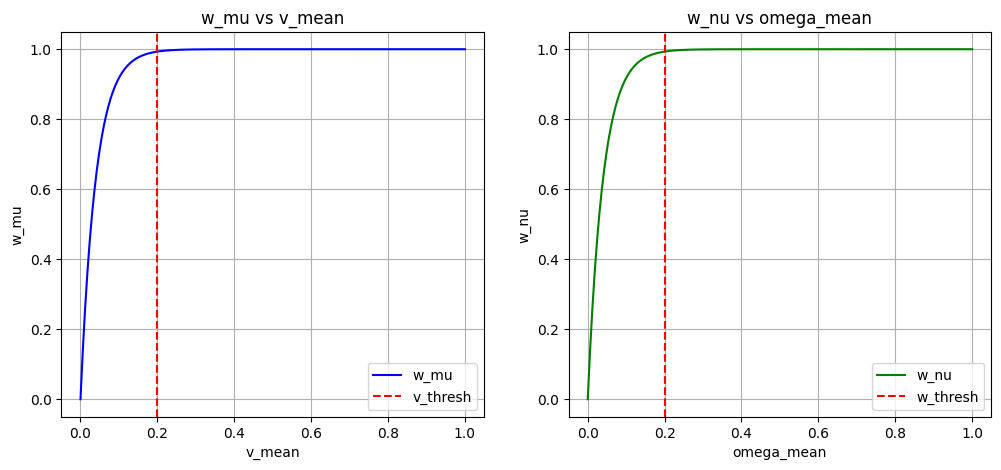

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from data_labeling_pipeline.hyperparameters import v_thresh, w_thresh

v_means = np.linspace(0, 1, 500)
omega_means = np.linspace(0, 1, 500)

w_mus = 1.0 - np.exp(-5.0 * v_means / v_thresh)
w_nus = 1.0 - np.exp(-5.0 * omega_means / w_thresh)


plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(v_means, w_mus, label="w_mu", color="blue")
plt.axvline(v_thresh, color="red", linestyle="--", label="v_thresh")
plt.title("w_mu vs v_mean")
plt.xlabel("v_mean")
plt.ylabel("w_mu")
plt.legend()
plt.grid()
plt.subplot(1, 2, 2)
plt.plot(omega_means, w_nus, label="w_nu", color="green")
plt.axvline(w_thresh, color="red", linestyle="--", label="w_thresh")
plt.title("w_nu vs omega_mean")
plt.xlabel("omega_mean")
plt.ylabel("w_nu")
plt.legend()
plt.grid()
plt.show()


In [ ]:
import plotly.graph_objects as go
from data_labeling_pipeline.hyperparameters import max_tie_strengh


## 3D plot: v_mean, omega_mean vs Coupling Strength
def cost_tie(v_mean, omega_mean):
    w_mu = 1.0 - np.exp(-5.0 * v_mean / v_thresh)
    w_nu = 1.0 - np.exp(-5.0 * omega_mean / w_thresh)
    return max_tie_strengh * ((1.0 - w_mu) * w_nu**2 + (1.0 - w_nu) * w_mu**2)


v_means = np.linspace(0, 1, 50)
omega_means = np.linspace(0, 1, 50)
v_grid, omega_grid = np.meshgrid(v_means, omega_means)
coupling_grid = cost_tie(v_grid, omega_grid)
fig = go.Figure(data=[go.Surface(z=coupling_grid, x=v_grid, y=omega_grid)])
fig.update_layout(
    title="v_mean and omega_mean vs Coupling Strength",
    scene=dict(
        xaxis_title="v_mean", yaxis_title="omega_mean", zaxis_title="Coupling Strength"
    ),
)
fig.show()

print(f"{cost_tie(0.5, 0.5)}")

7.453250792435398e-06


: 

In [ ]:
# for start in window_starts:
#     end = start + horizon_n
#     U_window = U[start:end]
#     Z_window = Z[start:end]

#     X_opt, m_opt, w_mu, w_nu = rhe.estimate(U_window, Z_window, step_size=step_size)

#     mu_true = np.mean(m_true[start:end, 0])
#     nu_true = np.mean(m_true[start:end, 1])

#     mu_err = abs(m_opt[0] - mu_true)
#     nu_err = abs(m_opt[1] - nu_true)

#     # Weight errors by confidence: well-excited windows matter more
#     # Add small baseline (0.1) so low-excitation windows still contribute
#     weight_mu = max(0.1, w_mu)
#     weight_nu = max(0.1, w_nu)

#     total_weighted_error += weight_mu * mu_err + weight_nu * nu_err
#     total_weight += weight_mu + weight_nu

#     # Optional: include state error (RMSE of X over the window) against ground truth
#     if state_weight > 0:
#         X_true_window = scenario.X_true[start:end]
#         # shape (N,3) -- compute RMSE over all state dims
#         diff = X_opt - X_true_window
#         diff
#         state_rmse = float(np.sqrt(np.mean((X_opt - X_true_window) ** 2)))
#         total_weighted_error += state_weight * state_rmse
#         total_weight += state_weight

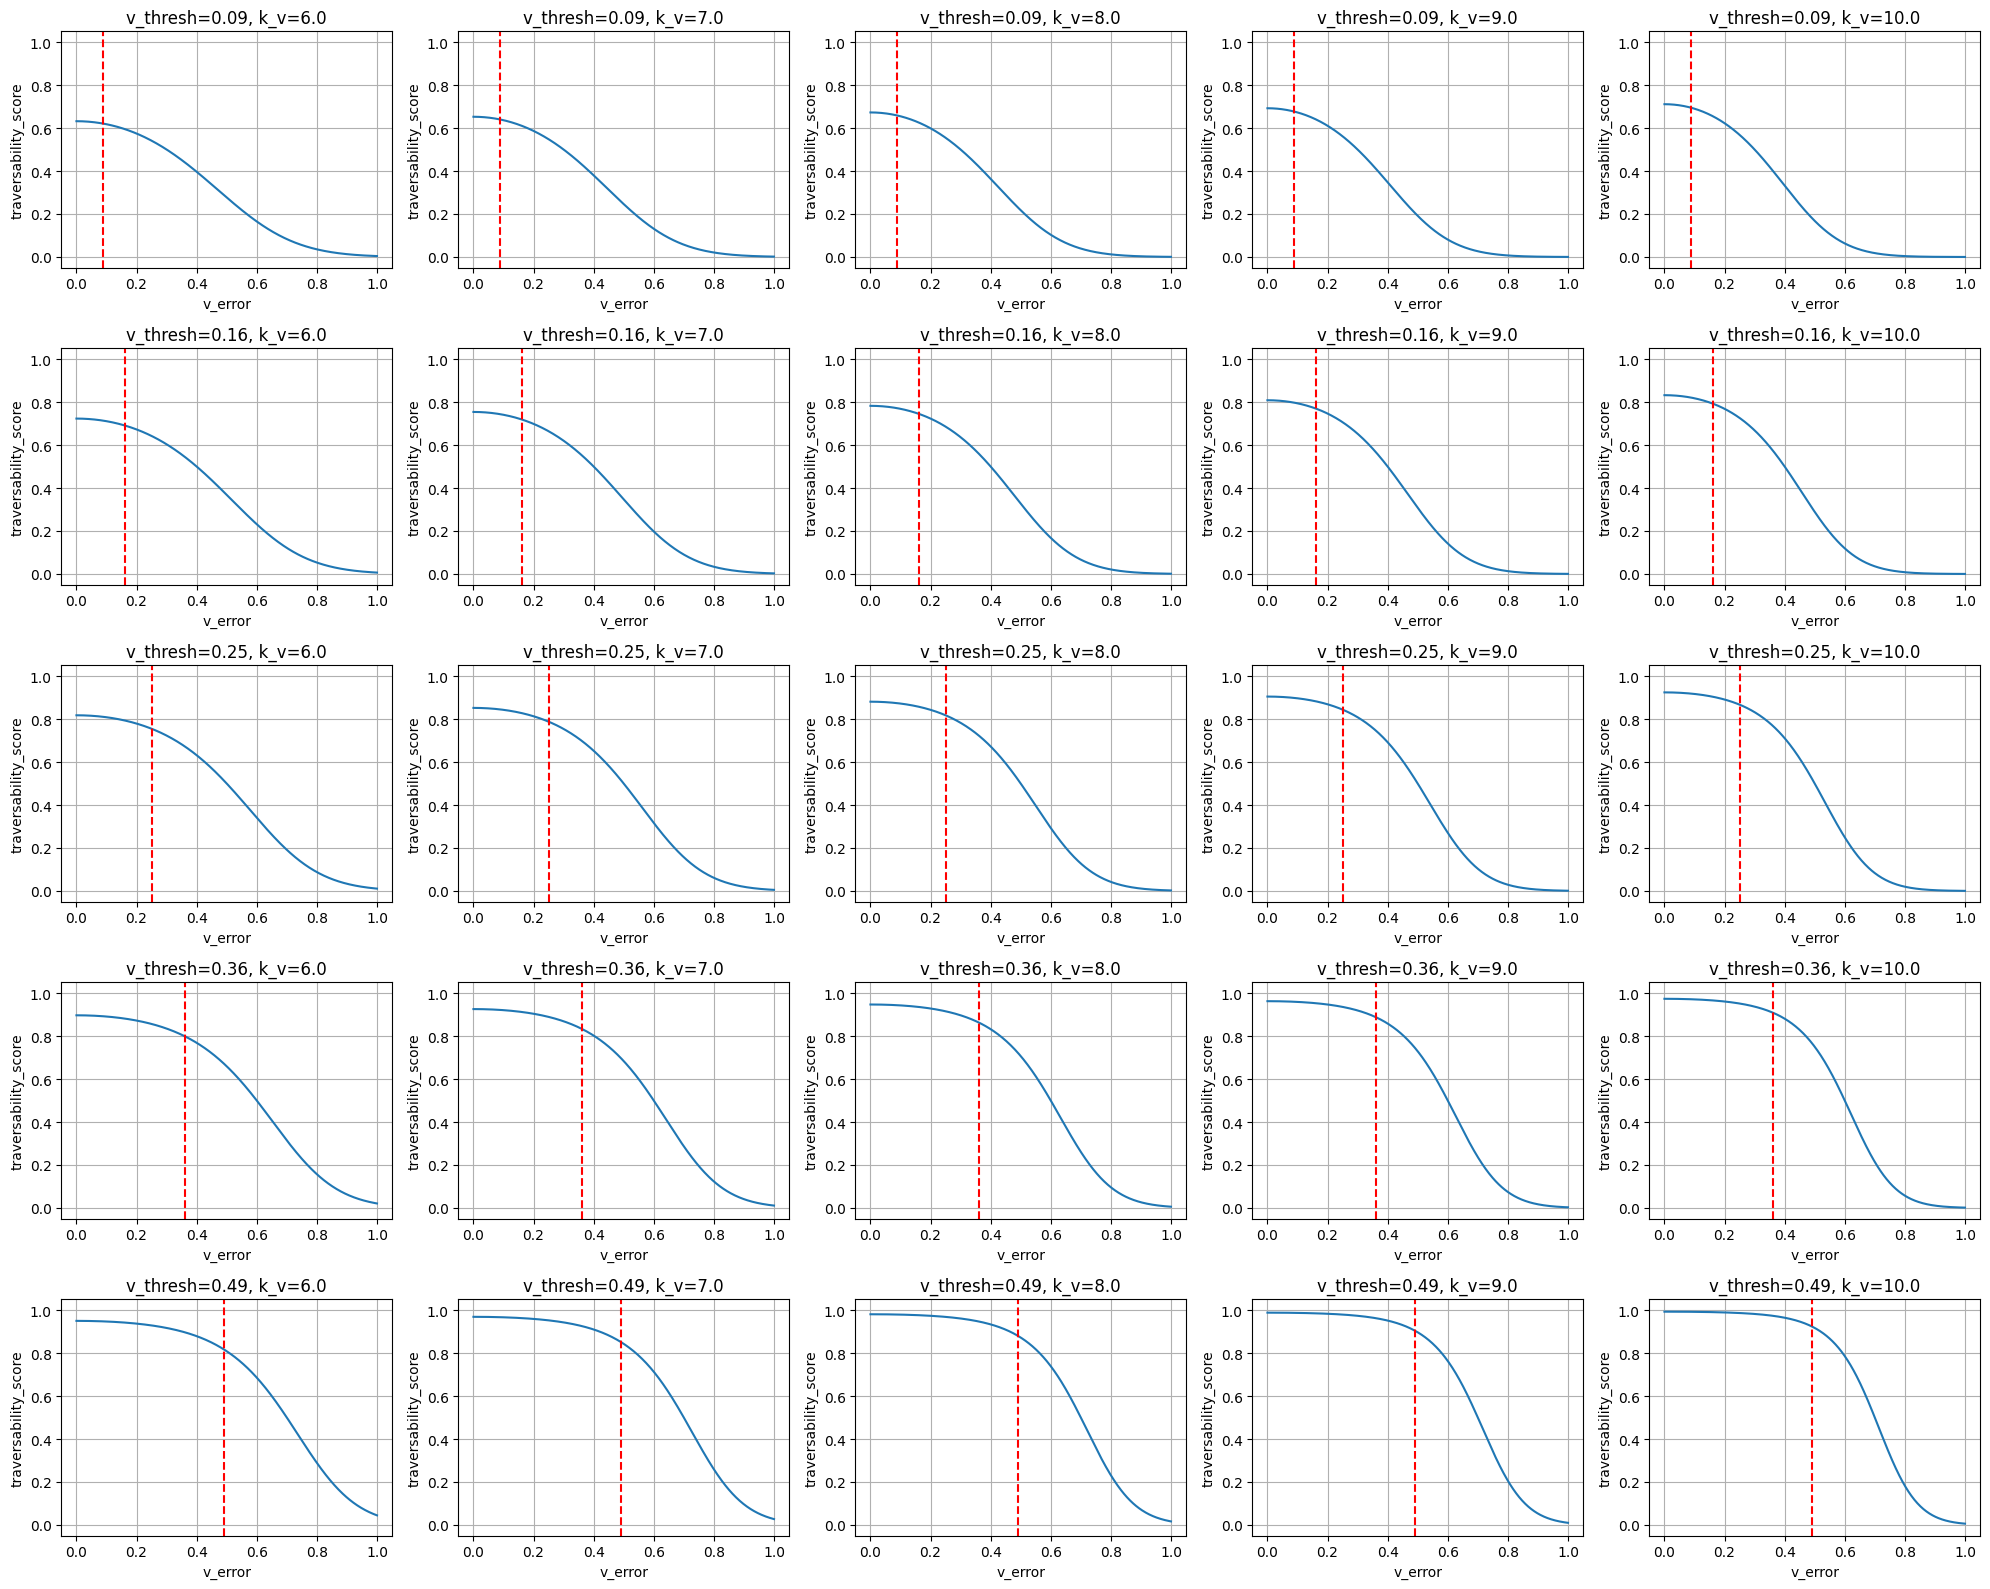

In [ ]:
v_thresh = 0.2  # err^2 lower than 0.4 --> traversability > 0.5
w_thresh = 0.2
k_v = 2
k_w = 2

v_threshs = np.linspace(0.3, 0.7, 5)
w_threshs = np.linspace(0.1, 0.5, 5)

k_vs = np.linspace(6, 10, 5)
k_ws = np.linspace(1, 5, 5)


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def traversability_score(error_signal, threshold, steepness):
    return sigmoid(-steepness * (error_signal**2 - threshold))


# Plot v_errors vs traversability score on a grid of plots for different thresholds and steepness values
v_errors = np.linspace(0, 1, 500)
plt.figure(figsize=(20, 16))
plot_idx = 1
for v_thresh in v_threshs:
    for k_v in k_vs:
        scores = traversability_score(v_errors, v_thresh, k_v)
        plt.subplot(len(v_threshs), len(k_vs), plot_idx)
        plt.plot(v_errors, scores, label=f"v_thresh={v_thresh:.2f}, k_v={k_v:.1f}")
        plt.axvline(v_thresh, color="red", linestyle="--")
        plt.title(f"v_thresh={v_thresh:.2f}, k_v={k_v:.1f}")
        plt.xlabel("v_error")
        plt.ylabel("traversability_score")
        plt.ylim(-0.05, 1.05)
        plt.grid()
        plot_idx += 1
plt.tight_layout()
plt.show()

In [ ]:
# Print x vs sqrt(x)